In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [3]:
data_path = path + '/diabetes_prediction_dataset.csv'

In [4]:
import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import f1_score, classification_report
from imblearn.over_sampling import SMOTE
from preprocessing import clean_and_encode
from bagging import bagging_sampler
from EDA import eda_process

In [ ]:
df1, df2 = eda_process(data_path, target_col='diabetes')
clean_data = clean_and_encode(df1, df2)['Dataset_2']
X_train_base, y_train_base = clean_data['X_train'], clean_data['y_train']
X_val_base, y_val_base = clean_data['X_val'], clean_data['y_val']
X_test_base, y_test_base = clean_data['X_test'], clean_data['y_test']


In [ ]:
X_train_base


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,glucose_hba1c_prod,risk_flag,bmi_log,gender_Male,gender_Other,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current,bmi_category_Obese,bmi_category_Overweight,bmi_category_Underweight
0,60.0,0,0,25.67,6.0,90,540.0,0,3.283539,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,28.0,0,0,25.36,3.5,160,560.0,0,3.271848,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,31.0,0,0,27.32,6.2,200,1240.0,0,3.343568,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,3.0,0,0,19.46,4.8,155,744.0,0,3.018472,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,45.0,0,1,20.31,6.2,130,806.0,1,3.059176,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67297,55.0,0,0,40.61,8.2,145,1189.0,0,3.728341,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
67298,68.0,0,0,27.32,6.2,90,558.0,0,3.343568,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
67299,27.0,0,0,20.48,3.5,159,556.5,0,3.067122,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
67300,70.0,1,1,41.35,6.0,280,1680.0,1,3.745968,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


Bagging
- Chọn ratio 0.5, đủ lớn để mô hình học (mỗi túi 33651 mẫu) và đủ nhỏ để mô hình SVM không bị tràn RAM

In [6]:
# bagging
my_bags = bagging_sampler(X_train_base, y_train_base, n_subsets=3, sample_size_ratio = 0.5)

BAGGING: Băm dữ liệu thành 3 tập Bootstrap
  Túi 1: Dữ liệu Train = 33651 mẫu | Dữ liệu OOB = 40808 mẫu (~60.6%)
  Túi 2: Dữ liệu Train = 33651 mẫu | Dữ liệu OOB = 40788 mẫu (~60.6%)
  Túi 3: Dữ liệu Train = 33651 mẫu | Dữ liệu OOB = 40778 mẫu (~60.6%)


Các thuật toán cơ sở

In [7]:
class LogisticRegressionManual:
    def __init__(self, learning_rate=0.1, epochs=2000, lambda_param=0.1, threshold=0.5):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.lambda_param = lambda_param
        self.threshold = threshold
        self.weights = None
        self.bias = None
        self.loss_history = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def _compute_loss(self, y, y_hat, m):
        core_loss = -(1/m) * np.sum(y * np.log(y_hat + 1e-15) + (1 - y) * np.log(1 - y_hat + 1e-15))
        l2_loss = (self.lambda_param / (2 * m)) * np.sum(np.square(self.weights))
        return core_loss + l2_loss

    def fit(self, X, y):
        X_np = np.asarray(X, dtype=np.float64)
        y_np = np.asarray(y, dtype=np.float64)

        m, n = X_np.shape

        self.weights = np.zeros(n)
        self.bias = 0
        self.loss_history = []

        for i in range(self.epochs):
            z = np.dot(X_np, self.weights) + self.bias
            y_hat = self._sigmoid(z)

            dw = (1/m) * np.dot(X_np.T, (y_hat - y_np))
            db = (1/m) * np.sum(y_hat - y_np)

            dw += (self.lambda_param / m) * self.weights # L2 regularization

            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db

            if i % 100 == 0:
                self.loss_history.append(self._compute_loss(y_np, y_hat, m))

        last_loss = self.loss_history[-1] if self.loss_history else 0
        print(f"  [LR-Manual] Done! Final Loss: {last_loss:.4f}")
        return self

    def predict_proba(self, X):
        if self.weights is None or self.bias is None:
            raise ValueError("Lỗi: Bạn phải gọi hàm .fit() trước khi dự đoán!")
        X_np = np.asarray(X, dtype=np.float64)
        z = np.dot(X_np, self.weights) + self.bias
        proba_positive = self._sigmoid(z)
        return np.array([[1 - p, p] for p in proba_positive])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= self.threshold).astype(int)

In [8]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report
from collections import Counter

def calculate_entropy(y):
    counts = np.bincount(y)
    probabilities = counts / len(y)
    return -np.sum([p * np.log2(p) for p in probabilities if p > 0])

def calculate_gini(y):
    counts = np.bincount(y)
    probabilities = counts / len(y)
    return 1 - np.sum(probabilities**2)

def split_data(X_column, threshold):
    left_idxs = np.argwhere(X_column <= threshold).flatten()
    right_idxs = np.argwhere(X_column > threshold).flatten()
    return left_idxs, right_idxs


def create_leaf_node(y_leaf):
        most_common = Counter(y_leaf).most_common(1)[0][0]
        counts = Counter(y_leaf)
        prob_0 = counts.get(0, 0) / len(y_leaf)
        prob_1 = counts.get(1, 0) / len(y_leaf)
        return {"value": most_common, "proba": [prob_0, prob_1]}

class DecisionTree_Scratch:
    def __init__(self, max_depth=5, min_samples_split=2, min_samples_leaf=1, criterion='entropy'):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.criterion = criterion
        self.tree = None
        self.feature_names = None

    def fit(self, X, y):
        if isinstance(X, pd.DataFrame):
            self.feature_names = X.columns.tolist()
            X_array = X.values
        else:
            self.feature_names = [f"Feature {i}" for i in range(X.shape[1])]
            X_array = np.asarray(X)

        y_array = np.asarray(y)

        self.tree = self.build_tree(X_array, y_array, depth=0)
        return self

    def build_tree(self, X, y, depth=0):
        n_samples, n_features = X.shape
        n_labels = len(np.unique(y))

        if (depth >= self.max_depth or n_labels == 1 or n_samples < self.min_samples_split):
            return create_leaf_node(y)

        best_feat, best_thresh = self.get_best_split(X, y, self.criterion)

        if best_feat is None:
            return create_leaf_node(y)

        left_idxs, right_idxs = split_data(X[:, best_feat], best_thresh)

        if len(left_idxs) < self.min_samples_leaf or len(right_idxs) < self.min_samples_leaf:
            return create_leaf_node(y)

        left_subtree = self.build_tree(X[left_idxs, :], y[left_idxs], depth + 1)
        right_subtree = self.build_tree(X[right_idxs, :], y[right_idxs], depth + 1)

        return {
            "feature_index": best_feat,
            "threshold": best_thresh,
            "left": left_subtree,
            "right": right_subtree
        }

    def predict_proba(self, X):
        X_array = np.asarray(X)
        return np.array([self.predict_proba_single(x, self.tree) for x in X_array])

    def predict(self, X):
        probabilities = self.predict_proba(X)
        return np.argmax(probabilities, axis=1)

    def predict_single(self, x, tree):
        if "value" in tree:
            return tree["value"]

        feature_val = x[tree["feature_index"]]
        if feature_val <= tree["threshold"]:
            return self.predict_single(x, tree["left"])
        else:
            return self.predict_single(x, tree["right"])

    def predict_proba_single(self, x, tree):
        if "proba" in tree:
            return tree["proba"]

        feature_val = x[tree["feature_index"]]
        if feature_val <= tree["threshold"]:
            return self.predict_proba_single(x, tree["left"])
        else:
            return self.predict_proba_single(x, tree["right"])



    def information_gain(self, y, X_column, threshold, criterion):
        if criterion == 'entropy':
            parent_impurity = calculate_entropy(y)
        else: # gini
            parent_impurity = calculate_gini(y)

        left_idxs, right_idxs = split_data(X_column, threshold)
        if len(left_idxs) == 0 or len(right_idxs) == 0:
            return 0

        n = len(y)

        if criterion == 'entropy':
            impurity_l = calculate_entropy(y[left_idxs])
            impurity_r = calculate_entropy(y[right_idxs])
        else: # gini
            impurity_l = calculate_gini(y[left_idxs])
            impurity_r = calculate_gini(y[right_idxs])

        child_impurity = (len(left_idxs) / n) * impurity_l + (len(right_idxs) / n) * impurity_r

        return parent_impurity - child_impurity

    def get_best_split(self, X, y, criterion):
        best_gain = -1
        split_idx, split_thresh = None, None
        n_features = X.shape[1]

        for feat_idx in range(n_features):
            X_column = X[:, feat_idx]
            thresholds = np.unique(X_column)

            for threshold in thresholds:
                gain = self.information_gain(y, X_column, threshold, criterion)
                if gain > best_gain:
                    best_gain = gain
                    split_idx = feat_idx
                    split_thresh = threshold

        return split_idx, split_thresh



In [ ]:
import numpy as np
from cvxopt import matrix, solvers

class SVMLD:
    def __init__(self, C=1.0, kernel='linear', degree=3, gamma=None, coef0=1):
        self.C = C
        self.kernel = kernel
        self.degree = degree
        self.gamma = gamma
        self.coef0 = coef0
        self.b = 0 
        self.alphas = None 
        self.sv_X = None 
        self.sv_y = None 

    def _kernel_function(self, x1, x2):
        if self.kernel == 'linear':
            return np.dot(x1, x2)

        elif self.kernel == 'poly':
            if self.gamma is None: self.gamma = 1.0 
            return (self.gamma * np.dot(x1, x2) + self.coef0) ** self.degree

        elif self.kernel == 'rbf':
            if self.gamma is None: self.gamma = 1.0 / len(x1) 
            return np.exp(-self.gamma * np.linalg.norm(x1 - x2) ** 2)

        elif self.kernel == 'sigmoid':
            if self.gamma is None: self.gamma = 1.0 
            return np.tanh(self.gamma * np.dot(x1, x2) + self.coef0)

    def _compute_gram_matrix(self, X):
        n_samples = X.shape[0]
        K = np.zeros((n_samples, n_samples))

        for i in range(n_samples):
            for j in range(n_samples):
                K[i, j] = self._kernel_function(X[i], X[j])

        return K

    def fit(self, X, y):
        n_samples, n_features = X.shape
        y = y.astype(float)

        y_svm = np.where(y == 0, -1, 1)

        if self.gamma is None:
            self.gamma = 1 / n_features

        # Gram matrix
        K = self._compute_gram_matrix(X)

        P = matrix(np.outer(y_svm, y_svm) * K)
        q = matrix(-np.ones(n_samples))

        G = matrix(np.vstack((
            -np.eye(n_samples),
            np.eye(n_samples)
        )))
        h = matrix(np.hstack((
            np.zeros(n_samples),
            np.ones(n_samples) * self.C
        )))

        A = matrix(y_svm.reshape(1, -1))
        b = matrix(np.zeros(1))

        solvers.options['show_progress'] = False
        solution = solvers.qp(P, q, G, h, A, b)

        alphas = np.ravel(solution['x'])

        # Support vectors
        sv = alphas > 1e-5
        self.alphas = alphas[sv]
        self.sv_X = X[sv]
        self.sv_y = y_svm[sv]

        # Bias
        self.b = 0
        for i in range(len(self.alphas)):
            s = 0
            for j in range(len(self.alphas)):
                s += self.alphas[j] * self.sv_y[j] * \
                     self._kernel_function(self.sv_X[j], self.sv_X[i])
            self.b += self.sv_y[i] - s
        self.b /= len(self.alphas)
        return self

    def decision_function(self, X):
        if self.alphas is None or self.sv_X is None or self.sv_y is None or self.b is None:
            raise ValueError("Model not fitted. Call fit() first.")

        decision_scores = []
        for x in X:
            s = 0
            for i in range(len(self.alphas)):
                s += self.alphas[i] * self.sv_y[i] * \
                     self._kernel_function(self.sv_X[i], x)
            decision_scores.append(s + self.b)
        return np.array(decision_scores)

    def predict(self, X):
        return (self.decision_function(X) >= 0).astype(int)

    def predict_proba(self, X):
        decision_scores = self.decision_function(X)
        clipped_scores = np.clip(decision_scores, -500, 500)
        proba_positive = 1 / (1 + np.exp(-clipped_scores))
        return np.array([[1 - p, p] for p in proba_positive])


In [ ]:
import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import f1_score, classification_report, roc_auc_score
from imblearn.over_sampling import SMOTE

class MedicalEnsemble:
    def __init__(self, random_state=42):
        self.random_state = random_state
        self.smote = SMOTE(random_state=self.random_state)

        self.models = [
            make_pipeline(
                StandardScaler(),
                LogisticRegressionManual(learning_rate=0.1, epochs=2000, lambda_param=0.1)
                ),
            DecisionTree_Scratch(
                max_depth=15,
                min_samples_split=20,
                min_samples_leaf=10,
                criterion='gini'
                ),
            make_pipeline(
                StandardScaler(),
                SVC(C=2000, kernel='rbf', gamma=0.05, probability = True)
                )
        ]
        self.model_names = ['Logistic Regression Manual', 'Decision Tree Scratch', 'SVM Scratch']

        self.trained_models = []
        self.weights = []
        self.best_threshold = 0.5

    def fit(self, bags, X_val, y_val):
        oob_f1_scores = []

        for model, name, bag in zip(self.models, self.model_names, bags):
            X_train_bag, y_train_bag = bag['train_X'], bag['train_y']
            X_oob, y_oob = bag['oob_X'], bag['oob_y']

            # SMOTE trên train bag
            X_smote, y_smote = self.smote.fit_resample(X_train_bag, y_train_bag)
            model.fit(X_smote, y_smote)
            self.trained_models.append(model)

            # Tính điểm F1 trên tập OOB
            oob_preds = model.predict(X_oob)
            f1 = f1_score(y_oob, oob_preds)
            oob_f1_scores.append(f1)
            print(f"[{name}] F1 OOB: {f1:.4f}")

        # Nguy cơ chia cho 0
        total_f1 = sum(oob_f1_scores)
        if total_f1 == 0:
            self.weights = np.ones(len(self.models)) / len(self.models)
        else:
            self.weights = np.array(oob_f1_scores) / total_f1

        print(f"Trọng số phân bổ: {dict(zip(self.model_names, np.round(self.weights, 3)))}")

        # Tìm Threshold tối ưu trên tập val 
        print("Tìm ngưỡng tối ưu (threeshold tuning)")
        val_probas = self._get_weighted_probas(X_val)

        thresholds = np.linspace(0.1, 0.9, 50)
        best_f1 = 0

        for t in thresholds:
            preds = (val_probas >= t).astype(int)
            f1 = f1_score(y_val, preds)
            if f1 > best_f1:
                best_f1 = f1
                self.best_threshold = t

        print(f"Ngưỡng (Threshold) tối ưu tìm được: {self.best_threshold:.3f} (Validation F1: {best_f1:.4f})")

    def _get_weighted_probas(self, X): # soft voting
        probas = np.array([m.predict_proba(X)[:, 1] for m in self.trained_models])

        #  weight soft voting: p1*w1 + p2*w2 + p3*w3
        return np.average(probas, axis=0, weights=self.weights)

    def predict(self, X, voting='soft'):
        if voting == 'soft':
            weighted_probas = self._get_weighted_probas(X)
            return (weighted_probas >= self.best_threshold).astype(int)

        elif voting == 'hard':
            preds = np.array([m.predict(X) for m in self.trained_models])
            sum_votes = np.sum(preds, axis=0)
            return (sum_votes >= 2).astype(int)


    def predict_proba_ensemble(self, X):
        return self._get_weighted_probas(X)

    def diversity_check(self, X_test):
        print("Kiểm tra mức độ đa dạng")
        preds = np.array([m.predict(X_test) for m in self.trained_models])
        corr_matrix = np.corrcoef(preds)

        df_corr = pd.DataFrame(corr_matrix, index=self.model_names, columns=self.model_names)
        print("Ma trận tương quan:")
        print(df_corr.round(3))

In [ ]:
import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import f1_score, classification_report, roc_auc_score, precision_score, recall_score, average_precision_score
from imblearn.over_sampling import SMOTE

ensemble_model = MedicalEnsemble(random_state=42)
ensemble_model.fit(my_bags, X_val_base, y_val_base)

ensemble_model.diversity_check(X_test_base)

print("\nĐánh giá kết quả trên tập test")
y_pred_ens = ensemble_model.predict(X_test_base)
y_proba_ens = ensemble_model.predict_proba_ensemble(X_test_base)

print("\nClassification Report của Ensemble")
print(classification_report(y_test_base, y_pred_ens))
print(f"ROC-AUC Score: {roc_auc_score(y_test_base, y_proba_ens):.4f}")

print("\nSo sánh với các mô hình cơ sở")
for name, model in zip(ensemble_model.model_names, ensemble_model.trained_models):
    preds = model.predict(X_test_base)
    probas = model.predict_proba(X_test_base)[:, 1] if hasattr(model, 'predict_proba') else model.decision_function(X_test_base)

    f1 = f1_score(y_test_base, preds)
    precision = precision_score(y_test_base, preds)
    recall = recall_score(y_test_base, preds)
    roc_auc = roc_auc_score(y_test_base, probas)
    pr_auc = average_precision_score(y_test_base, probas)
    print(f"Mô hình đơn: {name:20s} | F1-Score: {f1:.4f} | Precision: {precision:.4f} | Recall: {recall:.4f} | ROC-AUC: {roc_auc:.4f}, | PRC: {pr_auc:.4f}")

  [LR-Manual] Done! Final Loss: 0.2403


/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


[Logistic Regression Manual] F1 OOB: 0.5711
[Decision Tree Scratch] F1 OOB: 0.7227
[SVM Scratch] F1 OOB: 0.7048

[Trọng số phân bổ]: {'Logistic Regression Manual': np.float64(0.286), 'Decision Tree Scratch': np.float64(0.362), 'SVM Scratch': np.float64(0.353)}

Tìm ngưỡng tối ưu (threeshold tuning)


/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


Ngưỡng (Threshold) tối ưu tìm được: 0.622 (Validation F1: 0.7588)
Kiểm tra mức độ đa dạng


/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


Ma trận tương quan:
                            Logistic Regression Manual  Decision Tree Scratch  \
Logistic Regression Manual                       1.000                  0.597   
Decision Tree Scratch                            0.597                  1.000   
SVM Scratch                                      0.591                  0.694   

                            SVM Scratch  
Logistic Regression Manual        0.591  
Decision Tree Scratch             0.694  
SVM Scratch                       1.000  

Đánh giá kết quả trên tập test


/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(



Classification Report của Ensemble
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     13150
           1       0.85      0.72      0.78      1272

    accuracy                           0.96     14422
   macro avg       0.91      0.85      0.88     14422
weighted avg       0.96      0.96      0.96     14422

ROC-AUC Score: 0.9695

So sánh với các mô hình cơ sở
Mô hình đơn: Logistic Regression Manual | F1-Score: 0.5780 | Precision: 0.4321 | Recall: 0.8726 | ROC-AUC: 0.9595, | PRC: 0.8195


/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


Mô hình đơn: Decision Tree Scratch | F1-Score: 0.7259 | Precision: 0.6855 | Recall: 0.7712 | ROC-AUC: 0.9559, | PRC: 0.8480
Mô hình đơn: SVM Scratch          | F1-Score: 0.7265 | Precision: 0.7414 | Recall: 0.7123 | ROC-AUC: 0.9399, | PRC: 0.8041


In [ ]:
f1 = f1_score(y_test_base, y_pred_ens)
precision = precision_score(y_test_base, y_pred_ens)
recall = recall_score(y_test_base, y_pred_ens)
roc_auc = roc_auc_score(y_test_base, y_proba_ens)


print(f"F1-Score: {f1:.4f} | Precision: {precision:.4f} | Recall: {recall:.4f} | ROC-AUC: {roc_auc:.4f}")

F1-Score: 0.7826 | Precision: 0.8547 | Recall: 0.7217 | ROC-AUC: 0.9695


In [11]:
import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import f1_score, classification_report, roc_auc_score, precision_score, recall_score, average_precision_score
from imblearn.over_sampling import SMOTE

ensemble_model = MedicalEnsemble(random_state=42)
ensemble_model.fit(my_bags, X_val_base, y_val_base)

ensemble_model.diversity_check(X_test_base)

print("\nĐánh giá kết quả trên tập test")
y_pred_ens = ensemble_model.predict(X_test_base)
y_proba_ens = ensemble_model.predict_proba_ensemble(X_test_base)

print("\nClassification Report của Ensemble")
print(classification_report(y_test_base, y_pred_ens))
print(f"ROC-AUC Score: {roc_auc_score(y_test_base, y_proba_ens):.4f}")

print("\nSo sánh với các mô hình cơ sở")
for name, model in zip(ensemble_model.model_names, ensemble_model.trained_models):
    preds = model.predict(X_test_base)
    probas = model.predict_proba(X_test_base)[:, 1] if hasattr(model, 'predict_proba') else model.decision_function(X_test_base)

    f1 = f1_score(y_test_base, preds)
    precision = precision_score(y_test_base, preds)
    recall = recall_score(y_test_base, preds)
    roc_auc = roc_auc_score(y_test_base, probas)
    pr_auc = average_precision_score(y_test_base, probas)
    print(f"Mô hình đơn: {name:20s} | F1-Score: {f1:.4f} | Precision: {precision:.4f} | Recall: {recall:.4f} | ROC-AUC: {roc_auc:.4f}, | PRC: {pr_auc:.4f}")

  [LR-Manual] Done! Final Loss: 0.2376


/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


[Logistic Regression Manual] F1 OOB: 0.5740
[Decision Tree Scratch] F1 OOB: 0.7129
[SVM Scratch] F1 OOB: 0.7078

[Trọng số phân bổ]: {'Logistic Regression Manual': np.float64(0.288), 'Decision Tree Scratch': np.float64(0.357), 'SVM Scratch': np.float64(0.355)}

Tìm ngưỡng tối ưu (threeshold tuning)


/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


Ngưỡng (Threshold) tối ưu tìm được: 0.639 (Validation F1: 0.7682)
Kiểm tra mức độ đa dạng


/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


Ma trận tương quan:
                            Logistic Regression Manual  Decision Tree Scratch  \
Logistic Regression Manual                       1.000                  0.609   
Decision Tree Scratch                            0.609                  1.000   
SVM Scratch                                      0.649                  0.706   

                            SVM Scratch  
Logistic Regression Manual        0.649  
Decision Tree Scratch             0.706  
SVM Scratch                       1.000  

Đánh giá kết quả trên tập test


/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(



Classification Report của Ensemble
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     13150
           1       0.85      0.73      0.78      1272

    accuracy                           0.96     14422
   macro avg       0.91      0.86      0.88     14422
weighted avg       0.96      0.96      0.96     14422

ROC-AUC Score: 0.9694

So sánh với các mô hình cơ sở
Mô hình đơn: Logistic Regression Manual | F1-Score: 0.5839 | Precision: 0.4374 | Recall: 0.8781 | ROC-AUC: 0.9608, | PRC: 0.8253


/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


Mô hình đơn: Decision Tree Scratch | F1-Score: 0.7094 | Precision: 0.6579 | Recall: 0.7697 | ROC-AUC: 0.9549, | PRC: 0.8421
Mô hình đơn: SVM Scratch          | F1-Score: 0.7245 | Precision: 0.6940 | Recall: 0.7579 | ROC-AUC: 0.9510, | PRC: 0.8255


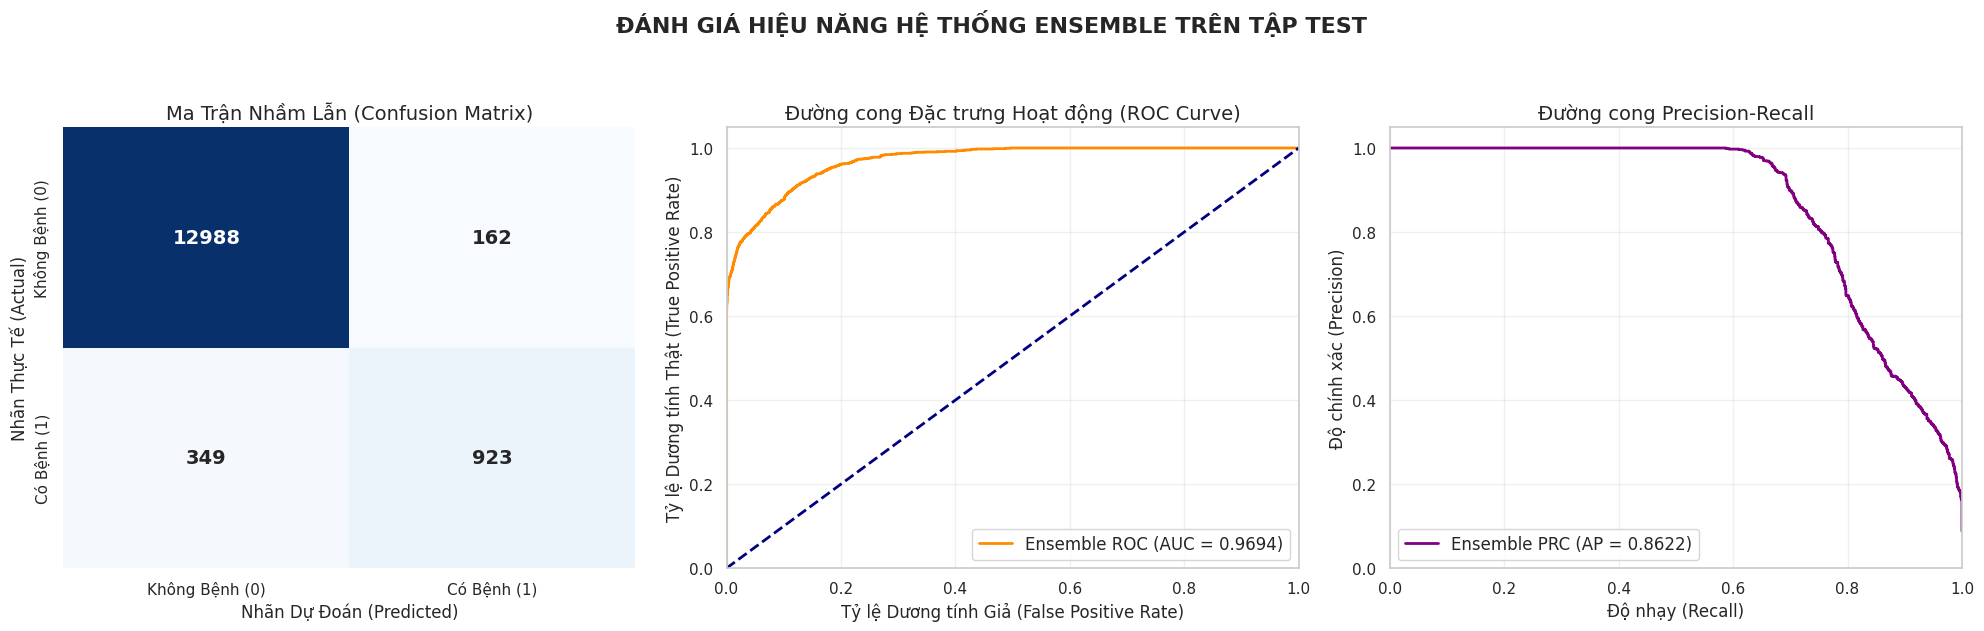

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve, average_precision_score

y_true = y_test_base.values

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('ĐÁNH GIÁ HIỆU NĂNG HỆ THỐNG ENSEMBLE TRÊN TẬP TEST', fontsize=16, fontweight='bold', y=1.05)


cm = confusion_matrix(y_true, y_pred_ens)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            annot_kws={"size": 14, "weight": "bold"}, cbar=False)
axes[0].set_title('Ma Trận Nhầm Lẫn (Confusion Matrix)', fontsize=14)
axes[0].set_xlabel('Nhãn Dự Đoán (Predicted)', fontsize=12)
axes[0].set_ylabel('Nhãn Thực Tế (Actual)', fontsize=12)
axes[0].xaxis.set_ticklabels(['Không Bệnh (0)', 'Có Bệnh (1)'])
axes[0].yaxis.set_ticklabels(['Không Bệnh (0)', 'Có Bệnh (1)'])


fpr, tpr, _ = roc_curve(y_true, y_proba_ens)
roc_auc = auc(fpr, tpr)

axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'Ensemble ROC (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('Tỷ lệ Dương tính Giả (False Positive Rate)', fontsize=12)
axes[1].set_ylabel('Tỷ lệ Dương tính Thật (True Positive Rate)', fontsize=12)
axes[1].set_title('Đường cong Đặc trưng Hoạt động (ROC Curve)', fontsize=14)
axes[1].legend(loc="lower right", fontsize=12)
axes[1].grid(alpha=0.3)


precision, recall, _ = precision_recall_curve(y_true, y_proba_ens)
pr_auc = average_precision_score(y_true, y_proba_ens)

axes[2].plot(recall, precision, color='purple', lw=2, label=f'Ensemble PRC (AP = {pr_auc:.4f})')
axes[2].set_xlim([0.0, 1.0])
axes[2].set_ylim([0.0, 1.05])
axes[2].set_xlabel('Độ nhạy (Recall)', fontsize=12)
axes[2].set_ylabel('Độ chính xác (Precision)', fontsize=12)
axes[2].set_title('Đường cong Precision-Recall', fontsize=14)
axes[2].legend(loc="lower left", fontsize=12)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


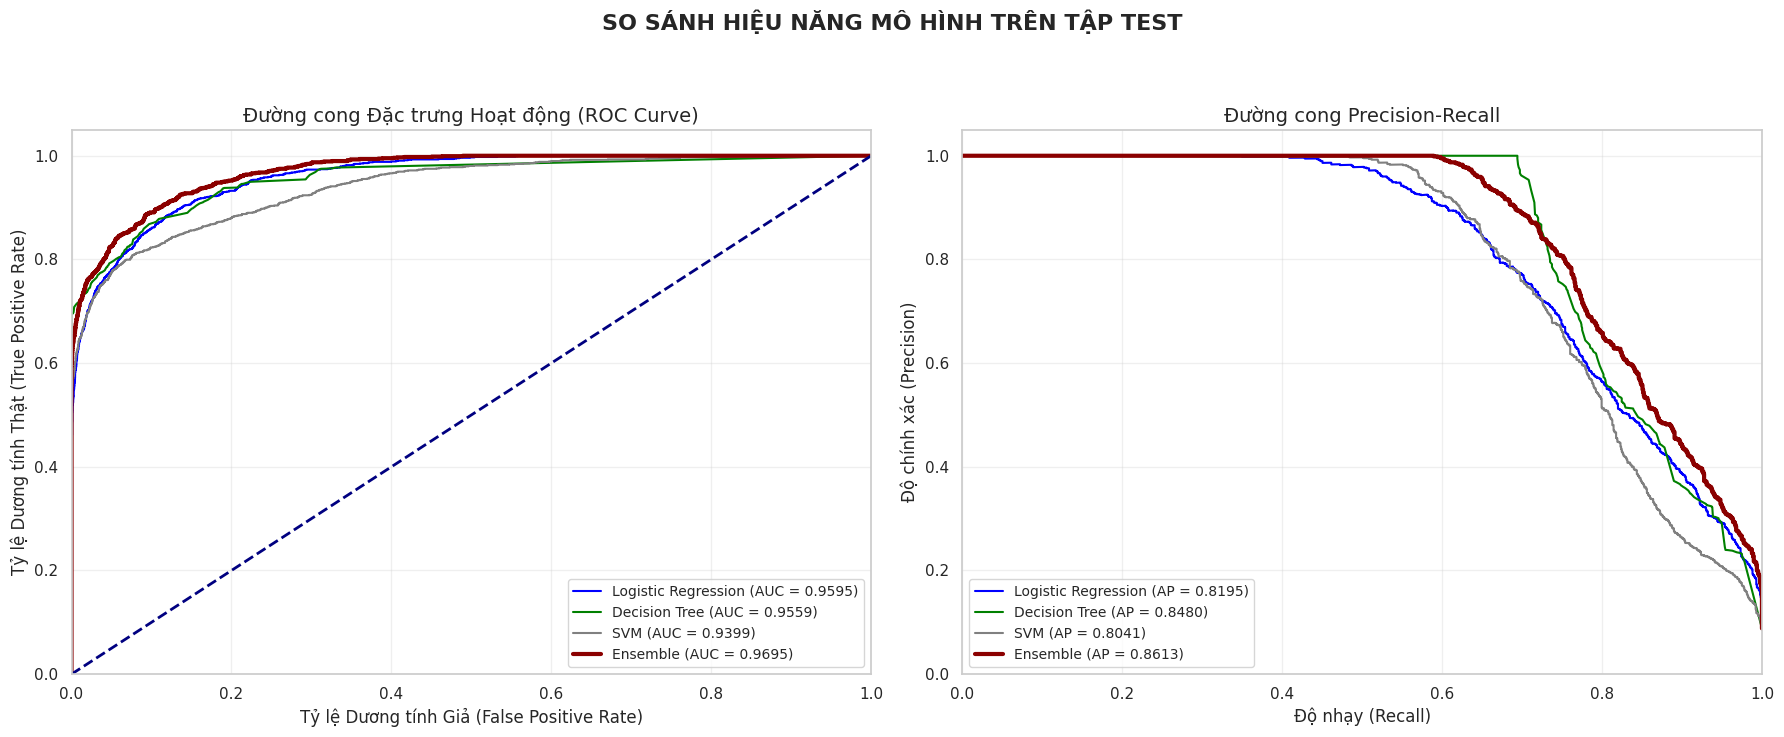

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve, average_precision_score

y_true = y_test_base.values

model_probas = {
    'Logistic Regression': ensemble_model.trained_models[0].predict_proba(X_test_base)[:, 1],
    'Decision Tree': ensemble_model.trained_models[1].predict_proba(X_test_base)[:, 1],
    'SVM': ensemble_model.trained_models[2].predict_proba(X_test_base)[:, 1],
    'Ensemble': ensemble_model.predict_proba_ensemble(X_test_base)
}

colors = {
    'Logistic Regression': 'blue',
    'Decision Tree': 'green',
    'SVM': 'gray',
    'Ensemble': 'darkred'
}

linestyles = {
    'Logistic Regression': '-',
    'Decision Tree': '-',
    'SVM': '-',
    'Ensemble': '-'
}

linewidths = {
    'Logistic Regression': 1.5,
    'Decision Tree': 1.5,
    'SVM': 1.5,
    'Ensemble': 3.0
}

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('SO SÁNH HIỆU NĂNG MÔ HÌNH TRÊN TẬP TEST', fontsize=16, fontweight='bold', y=1.05)

for name, probas in model_probas.items():
    fpr, tpr, _ = roc_curve(y_true, probas)
    roc_auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, color=colors[name], linestyle=linestyles[name],
                 linewidth=linewidths[name], label=f'{name} (AUC = {roc_auc:.4f})')

axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('Tỷ lệ Dương tính Giả (False Positive Rate)', fontsize=12)
axes[0].set_ylabel('Tỷ lệ Dương tính Thật (True Positive Rate)', fontsize=12)
axes[0].set_title('Đường cong Đặc trưng Hoạt động (ROC Curve)', fontsize=14)
axes[0].legend(loc="lower right", fontsize=10)
axes[0].grid(alpha=0.3)

# --- Precision-Recall Curve Plot ---
for name, probas in model_probas.items():
    precision, recall, _ = precision_recall_curve(y_true, probas)
    pr_auc = average_precision_score(y_true, probas)
    axes[1].plot(recall, precision, color=colors[name], linestyle=linestyles[name],
                 linewidth=linewidths[name], label=f'{name} (AP = {pr_auc:.4f})')

axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('Độ nhạy (Recall)', fontsize=12)
axes[1].set_ylabel('Độ chính xác (Precision)', fontsize=12)
axes[1].set_title('Đường cong Precision-Recall', fontsize=14)
axes[1].legend(loc="lower left", fontsize=10)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import joblib

joblib.dump(ensemble_model, 'diabetes_ensemble_model_new.pkl')

['diabetes_ensemble_model_new.pkl']

Đánh giá Dataset_1

In [ ]:
df1, df2 = eda_process(data_path, target_col='diabetes')
clean_data = clean_and_encode(df1, df2)['Dataset_1']
X_train_base, y_train_base = clean_data['X_train'], clean_data['y_train']
X_val_base, y_val_base = clean_data['X_val'], clean_data['y_val']
X_test_base, y_test_base = clean_data['X_test'], clean_data['y_test']

In [12]:
f1 = f1_score(y_test_base, y_pred_ens)
precision = precision_score(y_test_base, y_pred_ens)
recall = recall_score(y_test_base, y_pred_ens)
roc_auc = roc_auc_score(y_test_base, y_proba_ens)


print(f"F1-Score: {f1:.4f} | Precision: {precision:.4f} | Recall: {recall:.4f} | ROC-AUC: {roc_auc:.4f}")

F1-Score: 0.7832 | Precision: 0.8507 | Recall: 0.7256 | ROC-AUC: 0.9694


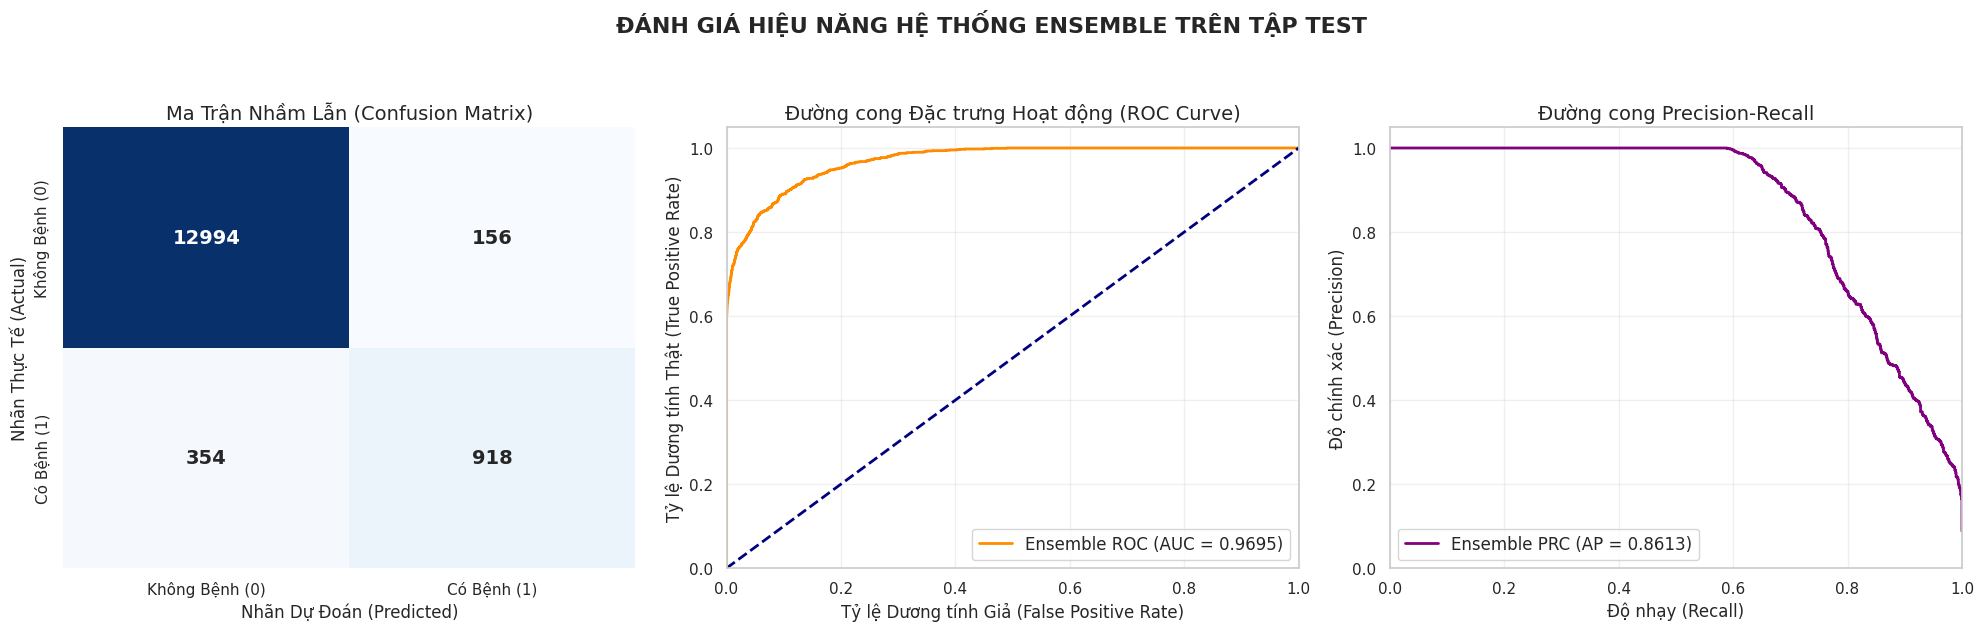

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve, average_precision_score

y_true = y_test_base.values

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('ĐÁNH GIÁ HIỆU NĂNG HỆ THỐNG ENSEMBLE TRÊN TẬP TEST', fontsize=16, fontweight='bold', y=1.05)


cm = confusion_matrix(y_true, y_pred_ens)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            annot_kws={"size": 14, "weight": "bold"}, cbar=False)
axes[0].set_title('Ma Trận Nhầm Lẫn (Confusion Matrix)', fontsize=14)
axes[0].set_xlabel('Nhãn Dự Đoán (Predicted)', fontsize=12)
axes[0].set_ylabel('Nhãn Thực Tế (Actual)', fontsize=12)
axes[0].xaxis.set_ticklabels(['Không Bệnh (0)', 'Có Bệnh (1)'])
axes[0].yaxis.set_ticklabels(['Không Bệnh (0)', 'Có Bệnh (1)'])


fpr, tpr, _ = roc_curve(y_true, y_proba_ens)
roc_auc = auc(fpr, tpr)

axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'Ensemble ROC (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('Tỷ lệ Dương tính Giả (False Positive Rate)', fontsize=12)
axes[1].set_ylabel('Tỷ lệ Dương tính Thật (True Positive Rate)', fontsize=12)
axes[1].set_title('Đường cong Đặc trưng Hoạt động (ROC Curve)', fontsize=14)
axes[1].legend(loc="lower right", fontsize=12)
axes[1].grid(alpha=0.3)


precision, recall, _ = precision_recall_curve(y_true, y_proba_ens)
pr_auc = average_precision_score(y_true, y_proba_ens)

axes[2].plot(recall, precision, color='purple', lw=2, label=f'Ensemble PRC (AP = {pr_auc:.4f})')
axes[2].set_xlim([0.0, 1.0])
axes[2].set_ylim([0.0, 1.05])
axes[2].set_xlabel('Độ nhạy (Recall)', fontsize=12)
axes[2].set_ylabel('Độ chính xác (Precision)', fontsize=12)
axes[2].set_title('Đường cong Precision-Recall', fontsize=14)
axes[2].legend(loc="lower left", fontsize=12)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()